# What the 2024 powerplay approach was worth in win-probability points

**The question, given the earlier findings.** The powerplay six rate rose about 40% with no measurable wicket cost, the expected wicket rate given situation was flat, and the cost per aggressive shot did not change. All of that is in runs and wickets. A coach thinks in the chance of winning. The provided win-probability column (`wprob`, the batting side's chance in percent) was shown in the validation notebook to be stated after each ball, so the ball-to-ball change is a price for what the ball produced: a six is worth some points, a wicket costs some. That makes it possible to put the 2024 powerplay approach into one number: how many win-probability points did the changed mix of outcomes buy?

**What this notebook does.** Because a calibrated probability is a martingale, the average change over balls is near zero in every season, so the value cannot be read as "win probability rose more in 2024". It is read as an accounting exercise on powerplay deliveries, under the match cluster bootstrap on shared draws:
1. *Outcome-mix ledger.* Each outcome (six, four, one to three runs, no run, wicket, wide, no ball, bye or leg bye) is priced as the mean change in wprob on balls with that outcome; the change in each outcome's share of deliveries is valued at fixed prices; the sum per 36-ball powerplay is the value of the approach. Prices are held at their 2023 level (primary), with pooled and 2024 prices for comparison, pooled over innings and per innings.
2. *Situational against realised wicket cost.* The change in expected wickets from the situational model and the change in the actual rate, each priced; the difference is the part of the wicket cost that was luck.
3. *What an aggressive shot was worth.* The wprob premium of an aggressive-shot ball over other balls, by season.

**How to read this notebook.** Points are percentage points of win probability per 36-ball powerplay. The ledger is invariant to a uniform drift in the model (shares sum to one, so a constant added to every price cancels) but not to a change in relative prices, so the 2023-price ledger is the primary read. The win-probability model is team-agnostic and its first-innings calibration is weaker than its second-innings one, and prices are averages over game states (a six at 0 for 2 is priced like one at 60 for 0). Descriptive throughout.

**Numbers in the text.** Quoted from the run of 9 September 2026 under the seed in `config.toml`; if a table disagrees with a paragraph, the table is current. Code lives in `scripts/win_probability_ledger/`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("scripts").resolve()))

from common.config import load_settings
from common import results_io
from mean_level_and_tail import season_contrast_bootstrap as scb
from win_probability_ledger import powerplay_ledger as wl

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

settings = load_settings()
ANALYSIS = "win_probability_ledger"
SEED = settings.seed("global")
N_ITER = settings.n_resamples
PRODUCER = "win_probability_ledger.ipynb"
YEARS = (settings.earlier_season, settings.later_season)
print(f"root={settings.root}  seed={SEED}  resamples={N_ITER}")

root=/Users/madkad/dpl_2026_s1  seed=202609081209  resamples=10000


## Data

In [2]:
DATA_PATH = settings.data_path("cleaned_dataset")
USING_FIXTURE = not DATA_PATH.exists()
if USING_FIXTURE:
    from common.synthetic_ballframe import make_synthetic_ballframe
    df = make_synthetic_ballframe(seed=7)
    print("REAL DATA ABSENT: running on the synthetic fixture (its wprob is noise; mechanics only)")
else:
    df = scb.load_cleaned_dataset(str(DATA_PATH))
print(f"rows={len(df):,}  matches={df['p_match'].nunique()}")
EXTRA = {"n_resamples": N_ITER, "fixture": USING_FIXTURE, "balls_per_powerplay": 36}

rows=34,967  matches=145


## Prices and the outcome-mix ledger

Per scope: each outcome's share of powerplay deliveries in both seasons with the change per 100 balls, its price per season and pooled; then the ledger at 2023, pooled and 2024 prices with the net per powerplay; the martingale-check rows give the mean change per ball per season scaled to a powerplay.

In [3]:
ledger = wl.powerplay_ledger(df, settings, SEED, N_ITER)
for name in ("prices", "ledger", "aggression"):
    results_io.write_table(ledger[name], settings, ANALYSIS, f"powerplay_{name}", SEED, PRODUCER, EXTRA)
print("powerplay deliveries priced:", ledger["n_balls"])
ledger["prices"][ledger["prices"]["scope"] == "both_innings"].round(3)

powerplay deliveries priced: 10534


,scope,outcome,share_2023,share_2024,share_change_per_100_balls,price_2023,price_2024,price_pooled,share_change_low,share_change_high,price_pooled_low,price_pooled_high
0,both_innings,six,0.045,0.063,1.789,4.968,4.260,4.555,0.712,2.899,4.222,4.882
1,both_innings,four,0.175,0.178,0.368,2.938,2.673,2.805,-1.084,1.865,2.668,2.940
2,both_innings,one_to_three,0.308,0.301,-0.619,0.144,0.089,0.117,-2.850,1.634,0.070,0.163
3,both_innings,no_run,0.379,0.357,-2.235,-1.025,-1.053,-1.039,-4.443,-0.058,-1.088,-0.989
4,both_innings,wicket,0.039,0.043,0.400,-4.320,-4.691,-4.515,-0.252,1.083,-4.912,-4.112
5,both_innings,wide,0.032,0.035,0.298,1.268,1.016,1.136,-0.445,1.030,0.956,1.317
6,both_innings,no_ball,0.005,0.005,-0.060,3.154,2.317,2.761,-0.395,0.259,1.913,3.646
7,both_innings,bye_or_leg_bye,0.018,0.018,0.058,0.183,0.445,0.316,-0.489,0.620,0.095,0.560


A powerplay six moved win probability by +5.0 points in 2023 (+4.3 in 2024), a four by +2.9, a dot by −1.0, a wicket by −4.3 (−4.7 in 2024); a wide is worth +1.3 and a no-ball +3.2. The mix moved by +1.8 sixes and −2.2 dots per 100 balls, +0.4 wickets and +0.4 fours. Boundaries were priced lower in 2024 than in 2023, which is why the ledger is read at fixed prices.

In [4]:
both = ledger["ledger"][ledger["ledger"]["scope"] == "both_innings"]
display(both[both["prices"] == f"prices_{YEARS[0]}"].round(3))
display(both[both["outcome"].isin(["net"]) | (both["prices"] == "martingale_check")].round(3))
ledger["ledger"][ledger["ledger"]["outcome"] == "net"].round(3)

,scope,prices,outcome,points_per_powerplay,ci_low,ci_high,p_positive
0,both_innings,prices_2023,six,3.200,1.265,5.207,NaN
1,both_innings,prices_2023,four,0.389,-1.155,1.982,NaN
2,both_innings,prices_2023,one_to_three,-0.032,-0.157,0.088,NaN
3,both_innings,prices_2023,no_run,0.825,0.021,1.658,NaN
4,both_innings,prices_2023,wicket,-0.623,-1.667,0.397,NaN
5,both_innings,prices_2023,wide,0.136,-0.204,0.480,NaN
6,both_innings,prices_2023,no_ball,-0.068,-0.478,0.290,NaN
7,both_innings,prices_2023,bye_or_leg_bye,0.004,-0.041,0.070,NaN
8,both_innings,prices_2023,net,3.831,0.233,7.592,0.982


,scope,prices,outcome,points_per_powerplay,ci_low,ci_high,p_positive
8,both_innings,prices_2023,net,3.831,0.233,7.592,0.982
17,both_innings,prices_pooled,net,3.533,0.049,7.018,0.976
26,both_innings,prices_2024,net,3.318,-0.102,6.640,0.972
27,both_innings,martingale_check,mean_delta_per_ball_2023,10.143,7.206,13.135,NaN
28,both_innings,martingale_check,mean_delta_per_ball_2024,8.858,5.820,11.782,NaN


,scope,prices,outcome,points_per_powerplay,ci_low,ci_high,p_positive
8,both_innings,prices_2023,net,3.831,0.233,7.592,0.982
17,both_innings,prices_pooled,net,3.533,0.049,7.018,0.976
26,both_innings,prices_2024,net,3.318,-0.102,6.640,0.972
37,first_innings,prices_2023,net,1.186,-4.094,6.592,0.659
46,first_innings,prices_pooled,net,1.082,-4.242,6.252,0.641
55,first_innings,prices_2024,net,1.040,-4.272,6.154,0.636
66,second_innings,prices_2023,net,6.528,1.788,11.347,0.997
75,second_innings,prices_pooled,net,5.961,1.445,10.362,0.995
84,second_innings,prices_2024,net,5.544,1.145,9.842,0.994


At 2023 prices the 2024 powerplay mix was worth +3.8 win-probability points per powerplay (interval +0.2 to +7.6, P 0.98). The extra sixes bought +3.2 (+1.3 to +5.2), the fewer dots +0.8 (+0.02 to +1.7), the extra fours +0.4, and the extra wickets cost −0.6 (−1.7 to +0.4). At pooled prices the net is +3.5 and at 2024 prices +3.3 (interval just touching zero). The value sits in the chase: +6.5 points per powerplay in second innings (+1.8 to +11.3) against +1.2 in first innings, which is noise on a wide interval. That is the same pattern the mechanics notebook found from the other side: the 2024 powerplay aggression, and its payoff, was in chasing innings.

The martingale check does not come out at zero: win probability rises by about 0.25 points per powerplay ball in both seasons, so the model under-rates the batting side at the start of an innings, more so in the first. The ledger is unaffected because that drift is uniform across outcomes, but it is a reason to trust the second-innings numbers more than the first.

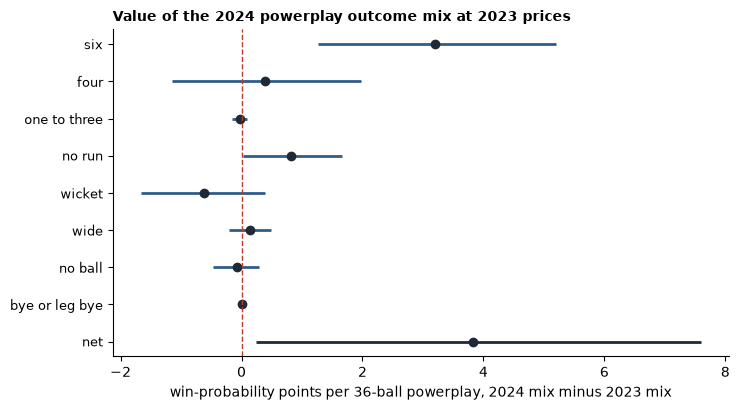

In [5]:
fig = wl.plot_ledger(ledger["ledger"], "both_innings", f"prices_{YEARS[0]}",
                     f"Value of the {YEARS[1]} powerplay outcome mix at {YEARS[0]} prices")
results_io.write_figure(fig, settings, ANALYSIS, "powerplay_ledger", SEED, PRODUCER)
plt.show()

## Situational against realised wicket cost

The wicket side at the pooled wicket price: the expected change from the situational model and the actual change, each priced per powerplay, and their difference.

In [6]:
xw_path = settings.output_dir("expected_wickets") / "powerplay_contrast.csv"
if xw_path.exists():
    xw = pd.read_csv(xw_path)
    xw = xw[(xw["variant"] == "situation") & (xw["role"] == "carrying")].set_index("quantity")
    args = (float(xw.loc["xw_change", "point"]), float(xw.loc["xw_change", "lo"]), float(xw.loc["xw_change", "hi"]),
            float(xw.loc["actual_change", "point"]), float(xw.loc["actual_change", "lo"]), float(xw.loc["actual_change", "hi"]))
    print("expected-wickets contrast read from", xw_path.name)
else:
    args = (0.0002, -0.0002, 0.0005, 0.0043, -0.0023, 0.0113)
    print("expected-wickets outputs not found; using the figures from the run of 9 September 2026")
wicket_side = wl.situational_vs_realised(ledger["prices"], *args)
results_io.write_table(wicket_side, settings, ANALYSIS, "wicket_side_situational_vs_realised", SEED, PRODUCER, EXTRA)
wicket_side.round(3)

expected-wickets contrast read from powerplay_contrast.csv


,side,wicket_rate_change_per_ball,wicket_price_points,points_per_powerplay,ci_low,ci_high
0,situational_expected_wickets,0.000,-4.515,-0.026,-0.076,0.024
1,realised_wicket_rate,0.004,-4.515,-0.706,-1.831,0.373
2,luck_component_realised_minus_expected,0.004,-4.515,-0.680,NaN,NaN


Priced at −4.5 points per wicket, the expected wicket cost of the 2024 approach was −0.03 points per powerplay (interval −0.08 to +0.02); the realised cost was −0.7 (−1.8 to +0.4); the −0.7 gap is the luck component. Set against the +3.2 the sixes bought, the approach was worth about +3.8 realised and about +4.5 in expectation. The wicket side of the ledger was never large enough to matter, and what there was of it was chance.

## What an aggressive shot was worth

The mean change in wprob on aggressive-shot balls against other balls, by season and scope, with the premium and its interval.

In [7]:
ledger["aggression"].round(3)

,scope,season,aggressive_balls,other_balls,price_aggressive,price_other,premium,premium_low,premium_high
0,both_innings,2023,821,4532,1.070,0.139,0.931,0.726,1.143
1,both_innings,2024,799,4382,0.688,0.166,0.522,0.263,0.770
2,first_innings,2023,369,2331,1.597,0.237,1.360,1.036,1.692
3,first_innings,2024,381,2202,0.752,0.155,0.597,0.241,0.934
4,second_innings,2023,452,2201,0.640,0.035,0.605,0.303,0.909
5,second_innings,2024,418,2180,0.629,0.176,0.453,0.129,0.781


An aggressive shot in the powerplay was worth +0.93 points more than another ball in 2023 (interval +0.73 to +1.14) and +0.52 in 2024 (+0.26 to +0.77): the premium roughly halved, with non-overlapping intervals, and the fall is sharpest in the first innings (1.36 to 0.60). The shot-level analysis found the wicket cost per aggressive shot unchanged, so the fall is in the reward, not the risk: boundaries were priced lower in 2024, which is what a model does when everyone is scoring more. Two readings coexist and cannot be separated with this model: diminishing returns to aggression as the league's baseline rose, and the provided model re-basing its expectations to 2024 scoring. Either way, each aggressive shot bought less in 2024 even as teams played more of them, and the approach still came out ahead because the volume rose.

The 2024 powerplay approach bought about four win-probability points per powerplay at 2023 prices, almost all from sixes, with the wicket cost too small to matter and mostly luck; the gain was concentrated in chases; and the marginal value of an aggressive shot fell by half as the baseline rose. In a coach's currency, the extra aggression paid, but with diminishing returns.